In [191]:
# importing libraries 
from pathlib import Path
from time import perf_counter
import json
import sys

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)
from sklearn.metrics import (
    accuracy_score,
    f1_score
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

In [192]:
# locating the project root directory

def find_project_root(start):
    start = Path(start).resolve()

    for directory in [start, *start.parents]:
        if (
            (directory / "src" / "preprocessing.py").is_file()
            and (directory / "data" / "processed" / "train_data.csv").is_file()
        ):
            return directory

    raise FileNotFoundError(
        "Could not locate the project root. "
        "Open the notebook from the ML assignment project."
    )


PROJECT_ROOT = find_project_root(Path.cwd())

MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

for directory in [MODEL_DIR, REPORT_DIR, FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import build_preprocessor, FEATURES

print("Project root:", PROJECT_ROOT)
print("Feature count:", len(FEATURES))

Project root: /Users/mohdaakilkhan/Documents/Aakil_MAC/BITS_Mtech/BITS MTECH Learning/SEM-1/ML/2026AJ05523_ML_Assignment_2
Feature count: 16


In [193]:
# loading the training data
TRAIN_PATH = (
    PROJECT_ROOT / "data" / "processed" / "train_data.csv"
)

train_df = pd.read_csv(TRAIN_PATH)

TARGET = "Class"

X_train = train_df[FEATURES].copy()
y_train = train_df[TARGET].copy()

assert len(FEATURES) == 16
assert X_train.shape[1] == 16
assert y_train.nunique() == 7
assert X_train.notna().all().all()
assert y_train.notna().all()

print("Training observations:", len(X_train))
print("Input features:", X_train.shape[1])
print("Classes:", sorted(y_train.unique()))

Training observations: 10834
Input features: 16
Classes: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']


In [194]:
# defining the models to evaluate
RANDOM_STATE = 42

MODEL_CONFIGS = {
    "Logistic Regression": {
        "filename": "logistic_regression.joblib",
        "scale": True,
        "classifier": LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE
        )
    },

    "Decision Tree": {
        "filename": "decision_tree.joblib",
        "scale": False,
        "classifier": DecisionTreeClassifier(
            max_depth=12,
            min_samples_leaf=3,
            random_state=RANDOM_STATE
        )
    },

    "KNN": {
        "filename": "knn.joblib",
        "scale": True,
        "classifier": KNeighborsClassifier(
            n_neighbors=7,
            weights="distance",
            n_jobs=1
        )
    },

    "Naive Bayes": {
        "filename": "naive_bayes.joblib",
        "scale": False,
        "classifier": GaussianNB()
    },

    "SVM": {
        "filename": "svm.joblib",
        "scale": True,
        "classifier": CalibratedClassifierCV(
            estimator=LinearSVC(
                C=1.0,
                dual=False,
                max_iter=5000,
                random_state=RANDOM_STATE
            ),
            method="sigmoid",
            cv=3
        )
    }
}

print("Number of model configurations:", len(MODEL_CONFIGS))

Number of model configurations: 5


In [195]:
# building reusable pipline
MODEL_PIPELINES = {}

for model_name, config in MODEL_CONFIGS.items():

    MODEL_PIPELINES[model_name] = Pipeline([
        (
            "preprocessing",
            build_preprocessor(scale=config["scale"])
        ),
        (
            "classifier",
            clone(config["classifier"])
        )
    ])

for model_name, pipeline in MODEL_PIPELINES.items():
    print(f"{model_name}:")
    print(pipeline)
    print("-" * 60)

Logistic Regression:
Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Area', 'Perimeter',
                                                   'MajorAxisLength',
                                                   'MinorAxisLength',
                                                   'AspectRation',
                                                   'Eccentricity', 'ConvexArea',
                                                   'EquivDiameter', 'Extent',
                                                   'Solidity', 'roundness',
                         

In [196]:
# coniguring the startified cross validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("Cross-validation folds:", cv.get_n_splits())

Cross-validation folds: 5


In [197]:
# comparing cross validation performance of the models
SCORING = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro",
    "macro_precision": "precision_macro",
    "macro_recall": "recall_macro"
}

In [198]:
# running five cross validation for each model
cv_results = []

for model_name, pipeline in MODEL_PIPELINES.items():

    print(f"\nEvaluating: {model_name}")

    start = perf_counter()

    scores = cross_validate(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=SCORING,
        n_jobs=1,
        return_train_score=False,
        error_score="raise"
    )

    elapsed = perf_counter() - start

    cv_results.append({
        "Model": model_name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Macro F1": scores["test_macro_f1"].mean(),
        "CV F1 Std": scores["test_macro_f1"].std(),
        "CV Precision": scores["test_macro_precision"].mean(),
        "CV Recall": scores["test_macro_recall"].mean(),
        "Mean Fit Time (s)": scores["fit_time"].mean(),
        "Mean Score Time (s)": scores["score_time"].mean(),
        "Total CV Time (s)": elapsed
    })

    print(
        "Macro F1:",
        round(scores["test_macro_f1"].mean(), 4)
    )

    print(
        "Total CV time:",
        round(elapsed, 2),
        "seconds"
    )


Evaluating: Logistic Regression
Macro F1: 0.9365
Total CV time: 0.82 seconds

Evaluating: Decision Tree
Macro F1: 0.9186
Total CV time: 0.7 seconds

Evaluating: KNN
Macro F1: 0.9367
Total CV time: 0.34 seconds

Evaluating: Naive Bayes
Macro F1: 0.7632
Total CV time: 0.2 seconds

Evaluating: SVM
Macro F1: 0.9316
Total CV time: 1.06 seconds


In [199]:
# creating comaprison table
cv_df = pd.DataFrame(cv_results)

cv_df = cv_df.sort_values(
    by="CV Macro F1",
    ascending=False
).reset_index(drop=True)

display(cv_df.round(4))

,Model,CV Accuracy,CV Macro F1,CV F1 Std,CV Precision,CV Recall,Mean Fit Time (s),Mean Score Time (s),Total CV Time (s)
0,KNN,0.9240,0.9367,0.0053,0.9389,0.9351,0.0219,0.0440,0.3389
1,Logistic Regression,0.9243,0.9365,0.0037,0.9378,0.9355,0.1036,0.0576,0.8244
2,SVM,0.9179,0.9316,0.0043,0.9340,0.9298,0.1899,0.0202,1.0595
3,Decision Tree,0.9054,0.9186,0.0041,0.9199,0.9175,0.1162,0.0212,0.6967
4,Naive Bayes,0.7620,0.7632,0.0085,0.7672,0.7647,0.0207,0.0176,0.2005


In [200]:
# saving cross validation results 
CV_RESULTS_PATH = REPORT_DIR / "cross_validation_results.csv"

cv_df.to_csv(CV_RESULTS_PATH, index=False)

print("Saved:", CV_RESULTS_PATH)

Saved: /Users/mohdaakilkhan/Documents/Aakil_MAC/BITS_Mtech/BITS MTECH Learning/SEM-1/ML/2026AJ05523_ML_Assignment_2/reports/cross_validation_results.csv


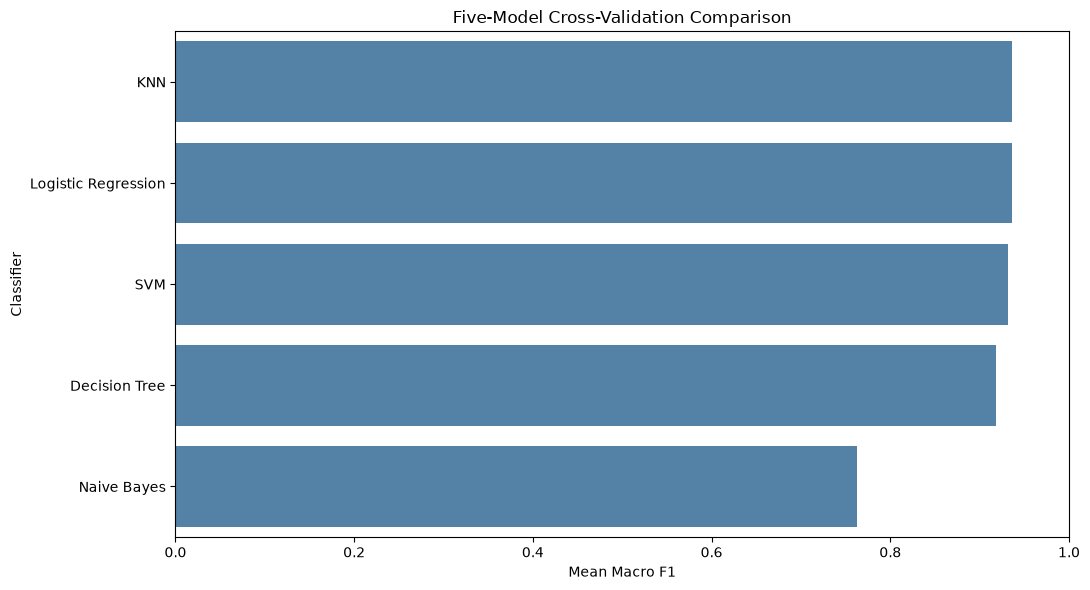

In [201]:
# visualize model comparison
fig, ax = plt.subplots(figsize=(11, 6))

sns.barplot(
    data=cv_df,
    x="CV Macro F1",
    y="Model",
    color="steelblue",
    ax=ax
)

ax.set_title("Five-Model Cross-Validation Comparison")
ax.set_xlabel("Mean Macro F1")
ax.set_ylabel("Classifier")
ax.set_xlim(0, 1)

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "cv_macro_f1_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

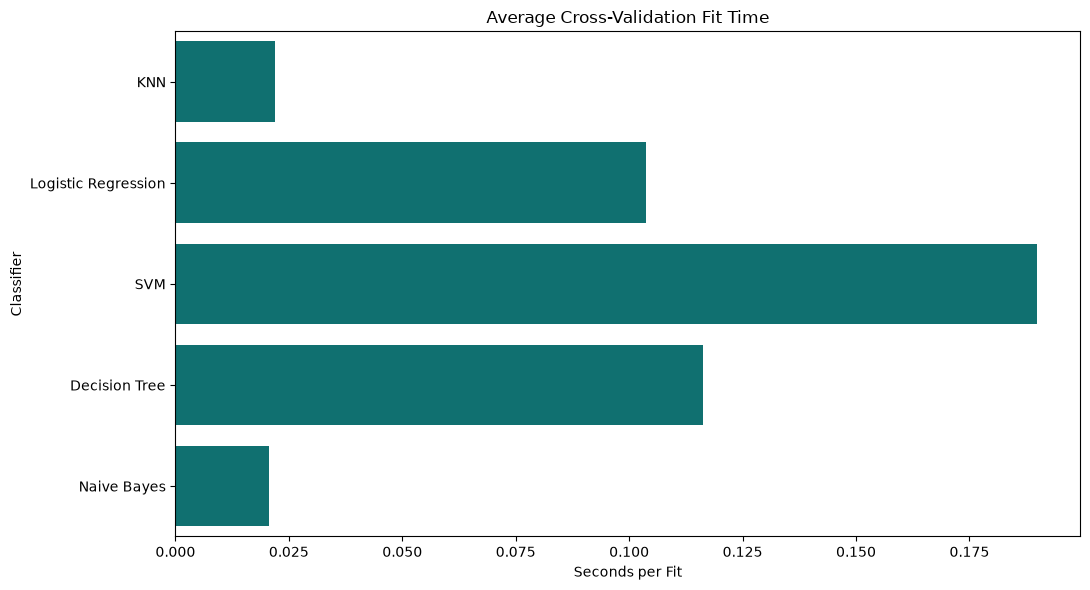

In [202]:
# comparing training time of the models
fig, ax = plt.subplots(figsize=(11, 6))

sns.barplot(
    data=cv_df,
    x="Mean Fit Time (s)",
    y="Model",
    color="teal",
    ax=ax
)

ax.set_title("Average Cross-Validation Fit Time")
ax.set_xlabel("Seconds per Fit")
ax.set_ylabel("Classifier")

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "cv_training_time.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [203]:
# fit and save models
fitted_models = {}
training_records = []

for model_name, pipeline in MODEL_PIPELINES.items():

    print(f"\nTraining final model: {model_name}")

    final_pipeline = clone(pipeline)

    start = perf_counter()

    final_pipeline.fit(X_train, y_train)

    fit_seconds = perf_counter() - start

    fitted_models[model_name] = final_pipeline

    filename = MODEL_CONFIGS[model_name]["filename"]
    model_path = MODEL_DIR / filename

    joblib.dump(final_pipeline, model_path)

    training_records.append({
        "Model": model_name,
        "Final Fit Time (s)": fit_seconds,
        "Artifact": filename,
        "Artifact Size (MB)": (
            model_path.stat().st_size / (1024 ** 2)
        )
    })

    print(f"Fit time: {fit_seconds:.3f} seconds")
    print("Saved:", model_path)


Training final model: Logistic Regression
Fit time: 0.107 seconds
Saved: /Users/mohdaakilkhan/Documents/Aakil_MAC/BITS_Mtech/BITS MTECH Learning/SEM-1/ML/2026AJ05523_ML_Assignment_2/models/logistic_regression.joblib

Training final model: Decision Tree
Fit time: 0.144 seconds
Saved: /Users/mohdaakilkhan/Documents/Aakil_MAC/BITS_Mtech/BITS MTECH Learning/SEM-1/ML/2026AJ05523_ML_Assignment_2/models/decision_tree.joblib

Training final model: KNN
Fit time: 0.026 seconds
Saved: /Users/mohdaakilkhan/Documents/Aakil_MAC/BITS_Mtech/BITS MTECH Learning/SEM-1/ML/2026AJ05523_ML_Assignment_2/models/knn.joblib

Training final model: Naive Bayes
Fit time: 0.024 seconds
Saved: /Users/mohdaakilkhan/Documents/Aakil_MAC/BITS_Mtech/BITS MTECH Learning/SEM-1/ML/2026AJ05523_ML_Assignment_2/models/naive_bayes.joblib

Training final model: SVM
Fit time: 0.237 seconds
Saved: /Users/mohdaakilkhan/Documents/Aakil_MAC/BITS_Mtech/BITS MTECH Learning/SEM-1/ML/2026AJ05523_ML_Assignment_2/models/svm.joblib


In [204]:
# inspect saved artifcat
training_df = pd.DataFrame(training_records)

display(training_df.round(3))

assert len(fitted_models) == 5

for model_name, config in MODEL_CONFIGS.items():
    path = MODEL_DIR / config["filename"]
    assert path.exists(), f"Missing model: {path}"

print("All five model artifacts saved successfully.")

,Model,Final Fit Time (s),Artifact,Artifact Size (MB)
0,Logistic Regression,0.107,logistic_regression.joblib,0.005
1,Decision Tree,0.144,decision_tree.joblib,0.089
2,KNN,0.026,knn.joblib,1.409
3,Naive Bayes,0.024,naive_bayes.joblib,0.005
4,SVM,0.237,svm.joblib,0.010


All five model artifacts saved successfully.


In [205]:
# bencharking the final models on the training data
benchmark_X = X_train.sample(
    n=min(500, len(X_train)),
    random_state=RANDOM_STATE
)

prediction_records = []

for model_name, model in fitted_models.items():

    # Warm-up prediction
    model.predict(benchmark_X.head(5))

    timings = []

    for _ in range(5):
        start = perf_counter()

        predictions = model.predict(benchmark_X)

        elapsed = perf_counter() - start
        timings.append(elapsed)

    prediction_records.append({
        "Model": model_name,
        "Rows": len(benchmark_X),
        "Mean Prediction Time (ms)": (
            np.mean(timings) * 1000
        ),
        "Prediction Time Std (ms)": (
            np.std(timings) * 1000
        ),
        "Milliseconds per Row": (
            np.mean(timings) * 1000 / len(benchmark_X)
        )
    })

prediction_df = pd.DataFrame(prediction_records)

display(prediction_df.round(4))

,Model,Rows,Mean Prediction Time (ms),Prediction Time Std (ms),Milliseconds per Row
0,Logistic Regression,500,1.1273,0.2702,0.0023
1,Decision Tree,500,1.0094,0.1184,0.0020
2,KNN,500,6.8065,0.5314,0.0136
3,Naive Bayes,500,1.2093,0.2426,0.0024
4,SVM,500,2.5018,0.1279,0.0050


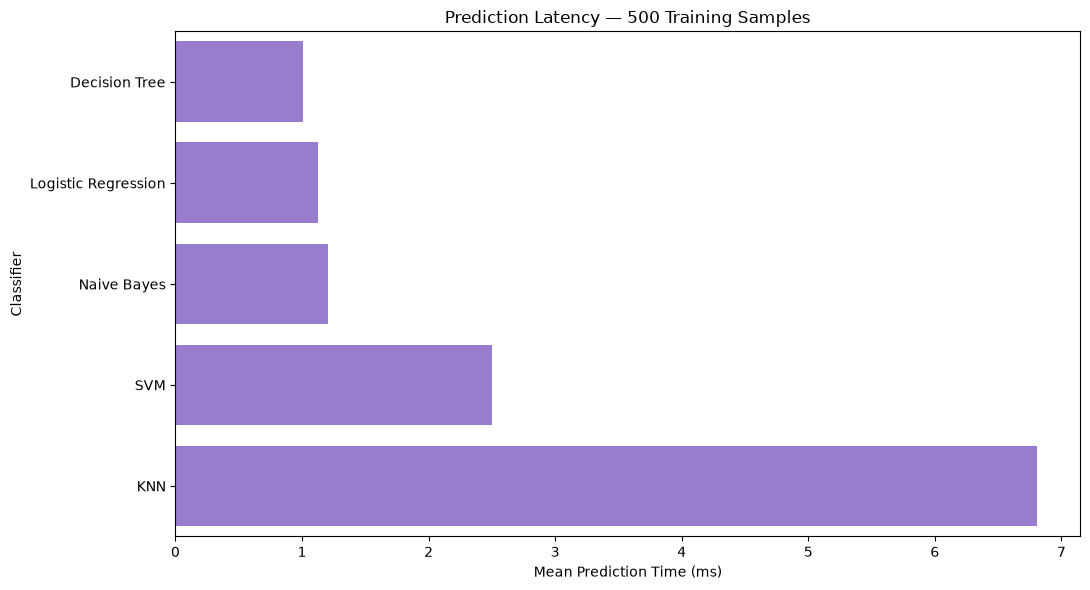

In [206]:
# save and visualize the prectiction time
prediction_df.to_csv(
    REPORT_DIR / "prediction_timing.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(11, 6))

sns.barplot(
    data=prediction_df.sort_values(
        "Mean Prediction Time (ms)"
    ),
    x="Mean Prediction Time (ms)",
    y="Model",
    color="mediumpurple",
    ax=ax
)

ax.set_title("Prediction Latency — 500 Training Samples")
ax.set_xlabel("Mean Prediction Time (ms)")
ax.set_ylabel("Classifier")

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "prediction_latency.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [207]:
# verification of model reloading 
reloaded_models = {}

for model_name, config in MODEL_CONFIGS.items():

    model_path = MODEL_DIR / config["filename"]

    loaded_model = joblib.load(model_path)

    reloaded_models[model_name] = loaded_model

    original_predictions = fitted_models[
        model_name
    ].predict(benchmark_X)

    reloaded_predictions = loaded_model.predict(
        benchmark_X
    )

    np.testing.assert_array_equal(
        original_predictions,
        reloaded_predictions
    )

    print(f"{model_name}: reload verified")

Logistic Regression: reload verified
Decision Tree: reload verified
KNN: reload verified
Naive Bayes: reload verified
SVM: reload verified


In [208]:
# multiclass classification probability 
for model_name, model in reloaded_models.items():

    probabilities = model.predict_proba(
        benchmark_X.head(20)
    )

    print(
        model_name,
        "Probability shape:",
        probabilities.shape
    )

    assert probabilities.shape == (20, 7)

    np.testing.assert_allclose(
        probabilities.sum(axis=1),
        np.ones(20),
        atol=1e-6
    )

    assert np.isfinite(probabilities).all()

print("All five models provide valid class probabilities.")

Logistic Regression Probability shape: (20, 7)
Decision Tree Probability shape: (20, 7)
KNN Probability shape: (20, 7)
Naive Bayes Probability shape: (20, 7)
SVM Probability shape: (20, 7)
All five models provide valid class probabilities.


In [209]:
# saving the model metadata
model_metadata = {
    "project": "Dry Bean Classification V2",
    "target": TARGET,
    "features": FEATURES,
    "classes": sorted(y_train.unique().tolist()),
    "model_files": {
        model_name: config["filename"]
        for model_name, config in MODEL_CONFIGS.items()
    },
    "default_selection": "All Models",
    "default_test_csv": "data/samples/default_test.csv",
    "random_state": RANDOM_STATE,
    "cv_folds": 5,
    "cv_primary_metric": "f1_macro",
    "training_rows": int(len(X_train))
}

metadata_path = MODEL_DIR / "model_metadata.json"

with open(metadata_path, "w") as file:
    json.dump(model_metadata, file, indent=4)

print(json.dumps(model_metadata, indent=4))

{
    "project": "Dry Bean Classification V2",
    "target": "Class",
    "features": [
        "Area",
        "Perimeter",
        "MajorAxisLength",
        "MinorAxisLength",
        "AspectRation",
        "Eccentricity",
        "ConvexArea",
        "EquivDiameter",
        "Extent",
        "Solidity",
        "roundness",
        "Compactness",
        "ShapeFactor1",
        "ShapeFactor2",
        "ShapeFactor3",
        "ShapeFactor4"
    ],
    "classes": [
        "BARBUNYA",
        "BOMBAY",
        "CALI",
        "DERMASON",
        "HOROZ",
        "SEKER",
        "SIRA"
    ],
    "model_files": {
        "Logistic Regression": "logistic_regression.joblib",
        "Decision Tree": "decision_tree.joblib",
        "KNN": "knn.joblib",
        "Naive Bayes": "naive_bayes.joblib",
        "SVM": "svm.joblib"
    },
    "default_selection": "All Models",
    "default_test_csv": "data/samples/default_test.csv",
    "random_state": 42,
    "cv_folds": 5,
    "cv_primary_

In [210]:
# saving consolidated training report
training_report = cv_df.merge(
    training_df,
    on="Model",
    how="left"
).merge(
    prediction_df,
    on="Model",
    how="left"
)

training_report = training_report.sort_values(
    "CV Macro F1",
    ascending=False
)

training_report_path = (
    REPORT_DIR / "model_training_report.csv"
)

training_report.to_csv(
    training_report_path,
    index=False
)

display(training_report.round(4))

,Model,CV Accuracy,CV Macro F1,CV F1 Std,CV Precision,CV Recall,Mean Fit Time (s),Mean Score Time (s),Total CV Time (s),Final Fit Time (s),Artifact,Artifact Size (MB),Rows,Mean Prediction Time (ms),Prediction Time Std (ms),Milliseconds per Row
0,KNN,0.9240,0.9367,0.0053,0.9389,0.9351,0.0219,0.0440,0.3389,0.0259,knn.joblib,1.4089,500,6.8065,0.5314,0.0136
1,Logistic Regression,0.9243,0.9365,0.0037,0.9378,0.9355,0.1036,0.0576,0.8244,0.1068,logistic_regression.joblib,0.0047,500,1.1273,0.2702,0.0023
2,SVM,0.9179,0.9316,0.0043,0.9340,0.9298,0.1899,0.0202,1.0595,0.2375,svm.joblib,0.0097,500,2.5018,0.1279,0.0050
3,Decision Tree,0.9054,0.9186,0.0041,0.9199,0.9175,0.1162,0.0212,0.6967,0.1435,decision_tree.joblib,0.0886,500,1.0094,0.1184,0.0020
4,Naive Bayes,0.7620,0.7632,0.0085,0.7672,0.7647,0.0207,0.0176,0.2005,0.0239,naive_bayes.joblib,0.0048,500,1.2093,0.2426,0.0024
